In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.signal import savgol_filter
from sklearn.decomposition import FastICA
import padasip as pa
import IPython.display as ipd

matplotlib.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

from setup_dsp import *


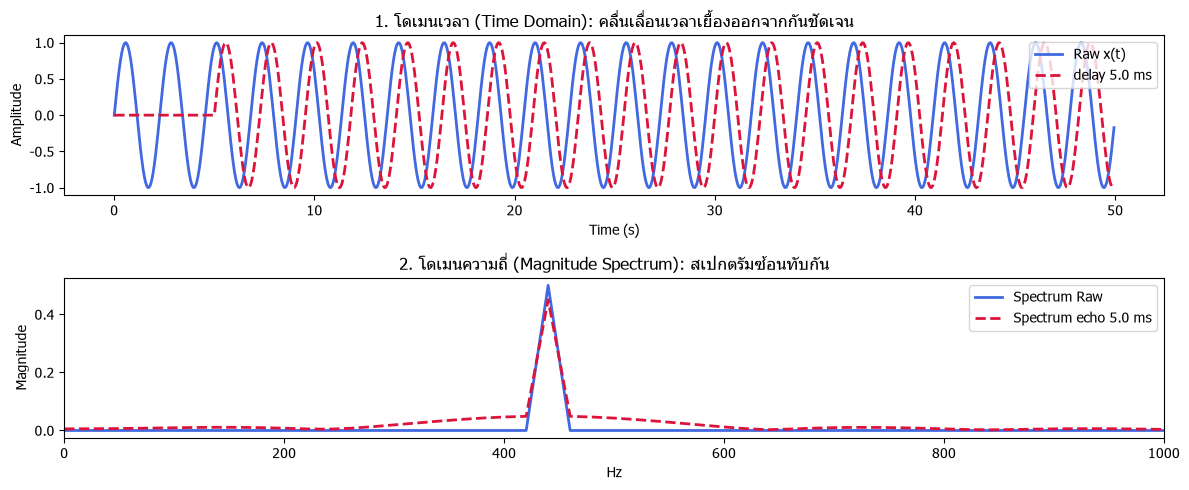

In [2]:
fs = 16000           
duration = 0.05
t = time_axis(fs, duration)
raw = generate_sine(440,t)
echo = generate_sine(440,t)
delay_ms = 5.0
delay_samples = int(fs * delay_ms / 1000.0)
echo = np.zeros_like(raw)
echo[delay_samples:] = raw[:-delay_samples]

N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N


plt.figure(figsize=(12,5))
plt.subplot(2,1,1)
plt.plot(t * 1000,raw, label="Raw x(t)", color="royalblue", lw=2)
plt.plot(t * 1000, echo, label=f"delay {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("1. โดเมนเวลา (Time Domain): คลื่นเลื่อนเวลาเยื้องออกจากกันชัดเจน")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.tight_layout()

plt.subplot(2,1,2)
plt.plot(freqs, mag_raw, label="Spectrum Raw", color="royalblue", lw=2)
plt.plot(freqs, mag_echo, label=f"Spectrum echo {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกัน")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.legend(loc="upper right")
plt.xlim(0, 1000)
plt.tight_layout()


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 20.00 ms (320 samples)


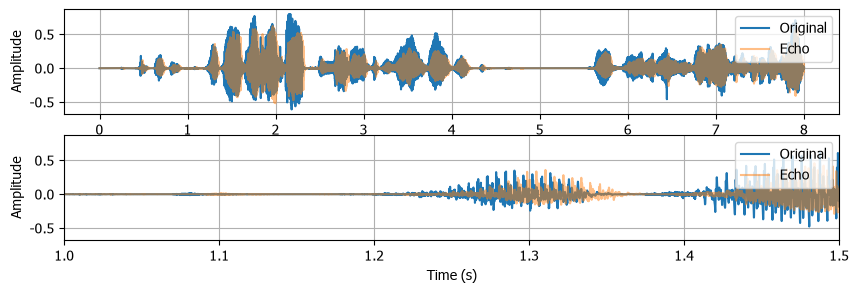

<Figure size 640x480 with 0 Axes>

In [3]:
t, raw, echo, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=20)

plt.figure(figsize=(10, 3))

plt.subplot(2,1,1)
plt.plot(t,raw, label ="Original")
plt.plot(t,echo, label ="Echo", alpha = 0.5)
plt.legend(loc="upper right")
plt.grid(True)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")


plt.subplot(2,1,2)
plt.plot(t,raw, label ="Original")
plt.plot(t,echo, label ="Echo", alpha = 0.5)
plt.xlim(1, 1.5)
plt.legend(loc="upper right")
plt.grid(True)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

plt.show()
plt.tight_layout()

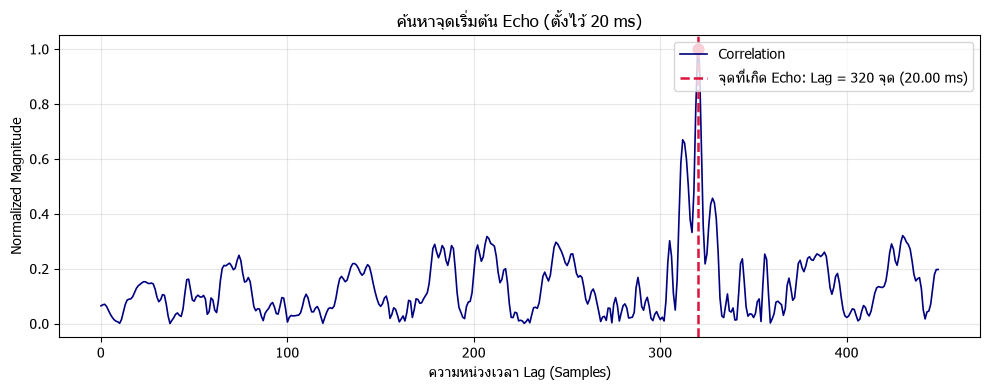

In [4]:
seg_len = fs * 1
corr = np.correlate(echo[:seg_len], raw[:seg_len], mode="full")
lags = np.arange(-seg_len + 1, seg_len)

max_lag_show = 450
zero_idx = seg_len - 1

lags_view = lags[zero_idx : zero_idx + max_lag_show]
corr_view = np.abs(corr[zero_idx : zero_idx + max_lag_show])
corr_view = corr_view / np.max(corr_view)

lag = lags_view[np.argmax(corr_view)]
ms = lag / fs * 1000

plt.figure(figsize=(10, 4))
plt.plot(lags_view, corr_view, color="navy", linewidth=1.2, label="Correlation")
plt.axvline(lag, color="crimson", linestyle="--", linewidth=1.8, label=f"จุดที่เกิด Echo: Lag = {lag} จุด ({ms:.2f} ms)")
plt.scatter([lag], [1.0], color="crimson", s=60, zorder=5)
plt.title("ค้นหาจุดเริ่มต้น Echo (ตั้งไว้ 20 ms)")
plt.xlabel("ความหน่วงเวลา Lag (Samples)")
plt.ylabel("Normalized Magnitude")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

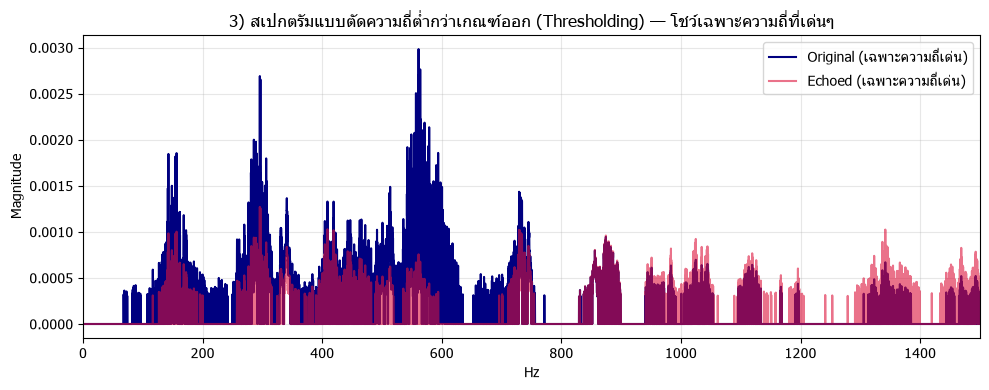

In [5]:
N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N

threshold = 0.1 * np.max(mag_raw)  #10%
mag_raw_dom = np.where(mag_raw >= threshold, mag_raw, 0)
mag_echo_dom = np.where(mag_echo >= threshold, mag_echo, 0)

plt.figure(figsize=(10, 4))
plt.plot(freqs, mag_raw_dom, label="Original (เฉพาะความถี่เด่น)", color="navy")
plt.plot(freqs, mag_echo_dom, label="Echoed (เฉพาะความถี่เด่น)", color="crimson", alpha=0.6)
plt.title("3) สเปกตรัมแบบตัดความถี่ต่ำกว่าเกณฑ์ออก (Thresholding) — โชว์เฉพาะความถี่ที่เด่นๆ")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.xlim(0, 1500)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


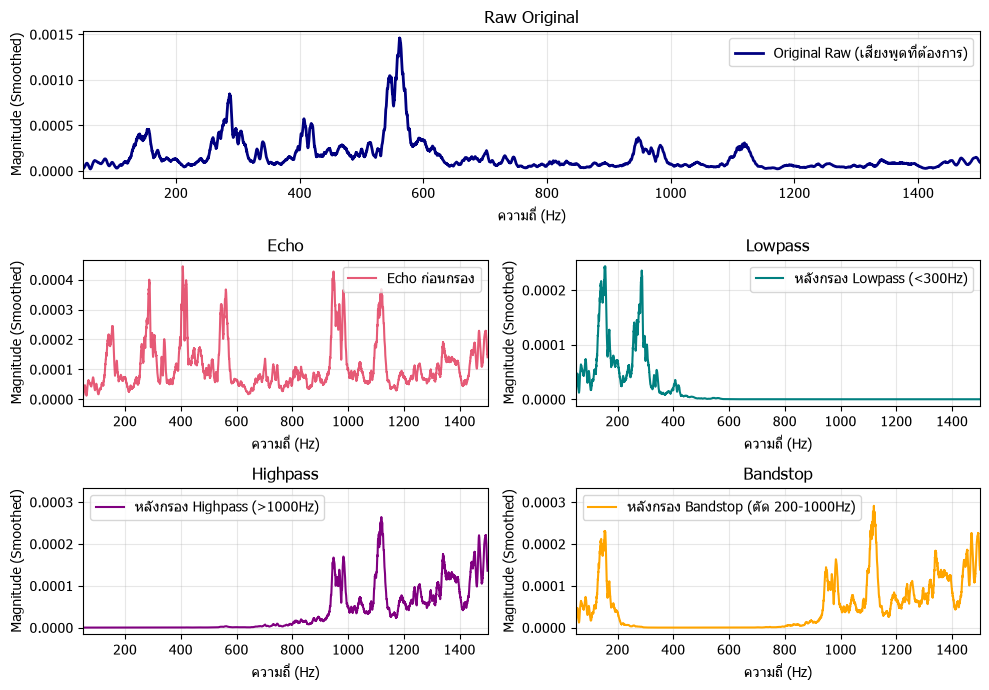

In [6]:
from scipy.signal.windows import hann

b_lp, a_lp = signal.butter(4, 300, btype="lowpass", fs=fs)
echo_lp = signal.filtfilt(b_lp, a_lp, echo)
b_hp, a_hp = signal.butter(4, 1000, btype="highpass", fs=fs)
echo_hp = signal.filtfilt(b_hp, a_hp, echo)
b_bs, a_bs = signal.butter(4, [200, 1000], btype="bandstop", fs=fs)
echo_bs = signal.filtfilt(b_bs, a_bs, echo)

def get_smooth_spectrum(sig, fs):
    w = np.hanning(len(sig))
    mag = np.abs(np.fft.rfft(sig * w)) / len(sig)
    return savgol_filter(mag, window_length=81, polyorder=3)

N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)

plt.figure(figsize=(10, 7))
plt.subplot(3, 1, 1)
plt.plot(freqs, get_smooth_spectrum(raw, fs), label="Original Raw (เสียงพูดที่ต้องการ)", color="navy", linewidth=2)
plt.title("Raw Original")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 3)
plt.plot(freqs, get_smooth_spectrum(echo, fs), label="Echo ก่อนกรอง", color="crimson", alpha=0.7)
plt.title("Echo")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 4)
plt.plot(freqs, get_smooth_spectrum(echo_lp, fs), label="หลังกรอง Lowpass (<300Hz)", color="teal")
plt.title("Lowpass")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 5)
plt.plot(freqs, get_smooth_spectrum(echo_hp, fs), label="หลังกรอง Highpass (>1000Hz)", color="purple")
plt.title("Highpass")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3, 2, 6)
plt.plot(freqs, get_smooth_spectrum(echo_bs, fs), label="หลังกรอง Bandstop (ตัด 200-1000Hz)", color="orange")
plt.title("Bandstop")
plt.xlabel("ความถี่ (Hz)")
plt.ylabel("Magnitude (Smoothed)")
plt.xlim(50, 1500)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
